In [4]:
!pip install -q xgboost lightgbm

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    GradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [6]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

Dataset Shape: (569, 30)
Target Shape: (569,)


In [7]:
print("Feature Names:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(data.target_names)

print("\nClass Distribution:")
print(y.value_counts())

Feature Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target Classes:
['malignant' 'benign']

Class Distribution:
target
1    357
0    212
Name: count, dtype: int64


In [8]:
print("Total Missing Values:", X.isnull().sum().sum())

Total Missing Values: 0


In [9]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


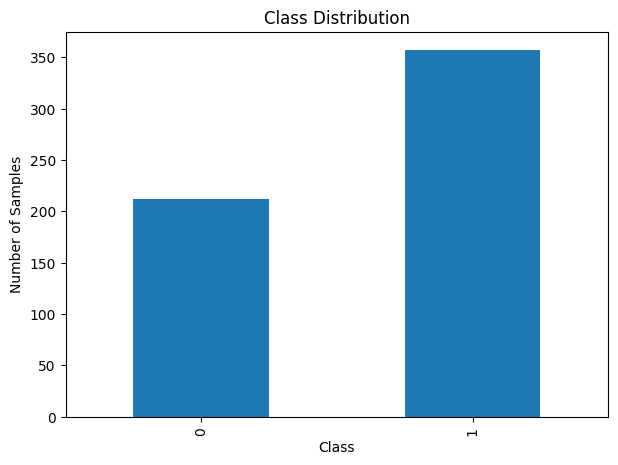

In [10]:
plt.figure(figsize=(7, 5))

y.value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution")

plt.show()

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [12]:
def evaluate_model(name, model):
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    precision = precision_score(y_test, y_test_pred)
    recall = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)

    if hasattr(model, "predict_proba"):
        y_probability = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_probability)
    else:
        roc_auc = np.nan

    print(f"\n{name}")
    print("-" * 50)
    print("Training Accuracy :", round(train_accuracy, 4))
    print("Testing Accuracy  :", round(test_accuracy, 4))
    print("Precision         :", round(precision, 4))
    print("Recall            :", round(recall, 4))
    print("F1 Score          :", round(f1, 4))
    print("ROC-AUC           :", round(roc_auc, 4))

    return {
        "Model": name,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }

In [13]:
baseline_model = DecisionTreeClassifier(
    random_state=42
)

baseline_result = evaluate_model(
    "Decision Tree",
    baseline_model
)


Decision Tree
--------------------------------------------------
Training Accuracy : 1.0
Testing Accuracy  : 0.9123
Precision         : 0.9559
Recall            : 0.9028
F1 Score          : 0.9286
ROC-AUC           : 0.9157


In [14]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

bagging_result = evaluate_model(
    "Bagging",
    bagging_model
)


Bagging
--------------------------------------------------
Training Accuracy : 1.0
Testing Accuracy  : 0.9386
Precision         : 0.9452
Recall            : 0.9583
F1 Score          : 0.9517
ROC-AUC           : 0.9927


In [15]:
boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

boosting_result = evaluate_model(
    "Gradient Boosting",
    boosting_model
)


Gradient Boosting
--------------------------------------------------
Training Accuracy : 1.0
Testing Accuracy  : 0.9561
Precision         : 0.9467
Recall            : 0.9861
F1 Score          : 0.966
ROC-AUC           : 0.9907


In [16]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_result = evaluate_model(
    "XGBoost",
    xgb_model
)


XGBoost
--------------------------------------------------
Training Accuracy : 1.0
Testing Accuracy  : 0.9474
Precision         : 0.9459
Recall            : 0.9722
F1 Score          : 0.9589
ROC-AUC           : 0.9934


In [17]:
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

lgbm_result = evaluate_model(
    "LightGBM",
    lgbm_model
)


LightGBM
--------------------------------------------------
Training Accuracy : 1.0
Testing Accuracy  : 0.9649
Precision         : 0.9595
Recall            : 0.9861
F1 Score          : 0.9726
ROC-AUC           : 0.9897


In [18]:
results = pd.DataFrame([
    baseline_result,
    bagging_result,
    boosting_result,
    xgb_result,
    lgbm_result
])

results

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,1.0,0.912281,0.955882,0.902778,0.928571,0.915675
1,Bagging,1.0,0.938596,0.945205,0.958333,0.951724,0.992725
2,Gradient Boosting,1.0,0.956140,0.946667,0.986111,0.965986,0.990741
3,XGBoost,1.0,0.947368,0.945946,0.972222,0.958904,0.993386
4,LightGBM,1.0,0.964912,0.959459,0.986111,0.972603,0.989749


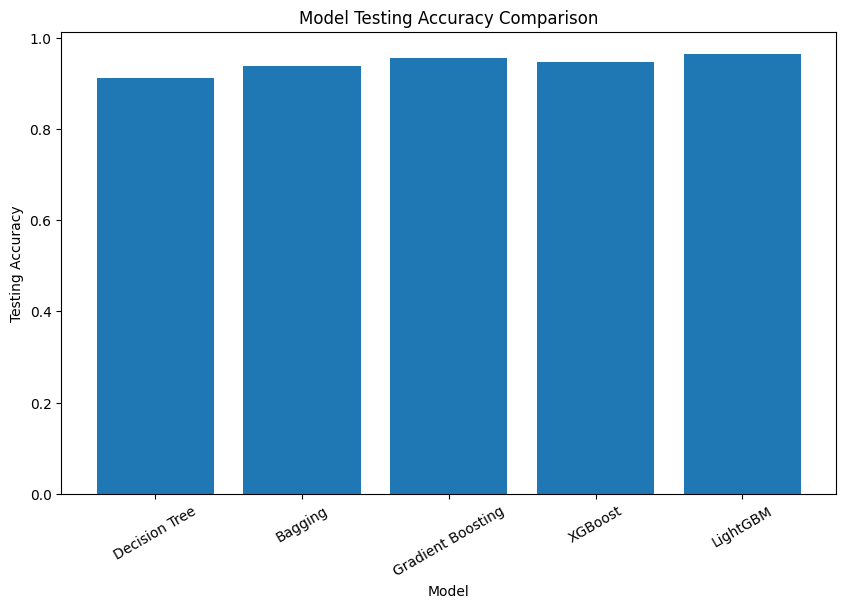

In [19]:
plt.figure(figsize=(10, 6))

plt.bar(
    results["Model"],
    results["Testing Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Testing Accuracy")
plt.title("Model Testing Accuracy Comparison")

plt.xticks(rotation=30)

plt.show()

In [20]:
comparison = results[
    ["Model", "Training Accuracy", "Testing Accuracy"]
].copy()

comparison

,Model,Training Accuracy,Testing Accuracy
0,Decision Tree,1.0,0.912281
1,Bagging,1.0,0.938596
2,Gradient Boosting,1.0,0.956140
3,XGBoost,1.0,0.947368
4,LightGBM,1.0,0.964912


In [21]:
results["Generalization Gap"] = (
    results["Training Accuracy"]
    - results["Testing Accuracy"]
)

results[
    [
        "Model",
        "Training Accuracy",
        "Testing Accuracy",
        "Generalization Gap"
    ]
]

,Model,Training Accuracy,Testing Accuracy,Generalization Gap
0,Decision Tree,1.0,0.912281,0.087719
1,Bagging,1.0,0.938596,0.061404
2,Gradient Boosting,1.0,0.956140,0.043860
3,XGBoost,1.0,0.947368,0.052632
4,LightGBM,1.0,0.964912,0.035088


In [22]:
depths = range(1, 16)

train_scores = []
test_scores = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_scores.append(
        model.score(X_train, y_train)
    )

    test_scores.append(
        model.score(X_test, y_test)
    )

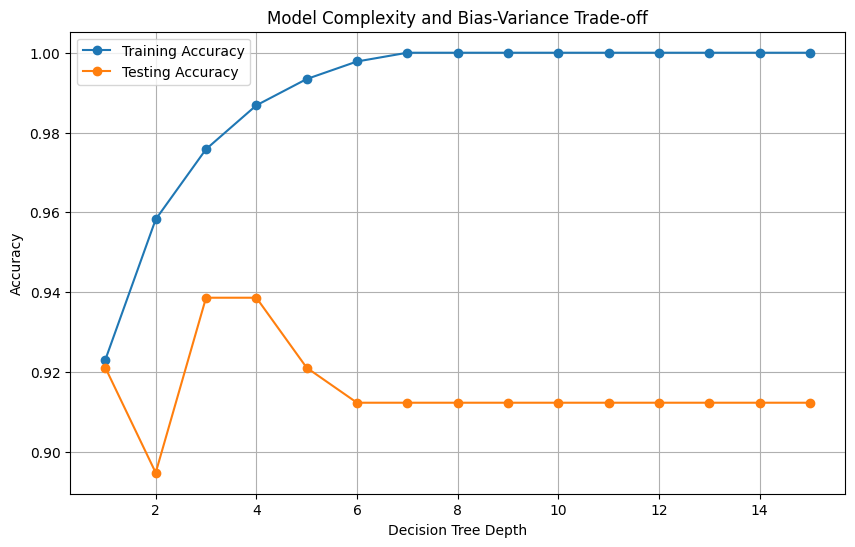

In [23]:
plt.figure(figsize=(10, 6))

plt.plot(
    depths,
    train_scores,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    test_scores,
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Decision Tree Depth")
plt.ylabel("Accuracy")
plt.title("Model Complexity and Bias-Variance Trade-off")

plt.legend()
plt.grid(True)

plt.show()

In [24]:
deep_tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

deep_tree.fit(X_train, y_train)

deep_train_accuracy = deep_tree.score(
    X_train,
    y_train
)

deep_test_accuracy = deep_tree.score(
    X_test,
    y_test
)

print("Training Accuracy:", deep_train_accuracy)
print("Testing Accuracy :", deep_test_accuracy)
print(
    "Generalization Gap:",
    deep_train_accuracy - deep_test_accuracy
)

Training Accuracy: 1.0
Testing Accuracy : 0.9122807017543859
Generalization Gap: 0.08771929824561409


In [25]:
simple_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

simple_tree.fit(X_train, y_train)

simple_train_accuracy = simple_tree.score(
    X_train,
    y_train
)

simple_test_accuracy = simple_tree.score(
    X_test,
    y_test
)

print("Training Accuracy:", simple_train_accuracy)
print("Testing Accuracy :", simple_test_accuracy)

Training Accuracy: 0.9230769230769231
Testing Accuracy : 0.9210526315789473


In [26]:
l1_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=1.0,
            max_iter=5000,
            random_state=42
        )
    )
])

l1_result = evaluate_model(
    "Logistic Regression - L1",
    l1_model
)


Logistic Regression - L1
--------------------------------------------------
Training Accuracy : 0.989
Testing Accuracy  : 0.9912
Precision         : 0.9863
Recall            : 1.0
F1 Score          : 0.9931
ROC-AUC           : 0.9967


In [27]:
l2_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            penalty="l2",
            solver="lbfgs",
            C=1.0,
            max_iter=5000,
            random_state=42
        )
    )
])

l2_result = evaluate_model(
    "Logistic Regression - L2",
    l2_model
)


Logistic Regression - L2
--------------------------------------------------
Training Accuracy : 0.989
Testing Accuracy  : 0.9825
Precision         : 0.9861
Recall            : 0.9861
F1 Score          : 0.9861
ROC-AUC           : 0.9954


In [28]:
regularization_results = pd.DataFrame([
    l1_result,
    l2_result
])

regularization_results

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression - L1,0.989011,0.991228,0.986301,1.000000,0.993103,0.996693
1,Logistic Regression - L2,0.989011,0.982456,0.986111,0.986111,0.986111,0.995370


In [29]:
C_values = [0.01, 0.1, 1, 10, 100]

l1_scores = []
l2_scores = []

for C in C_values:

    l1 = Pipeline([
        ("scaler", StandardScaler()),
        (
            "classifier",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=C,
                max_iter=5000
            )
        )
    ])

    l2 = Pipeline([
        ("scaler", StandardScaler()),
        (
            "classifier",
            LogisticRegression(
                penalty="l2",
                solver="lbfgs",
                C=C,
                max_iter=5000
            )
        )
    ])

    l1.fit(X_train, y_train)
    l2.fit(X_train, y_train)

    l1_scores.append(
        l1.score(X_test, y_test)
    )

    l2_scores.append(
        l2.score(X_test, y_test)
    )

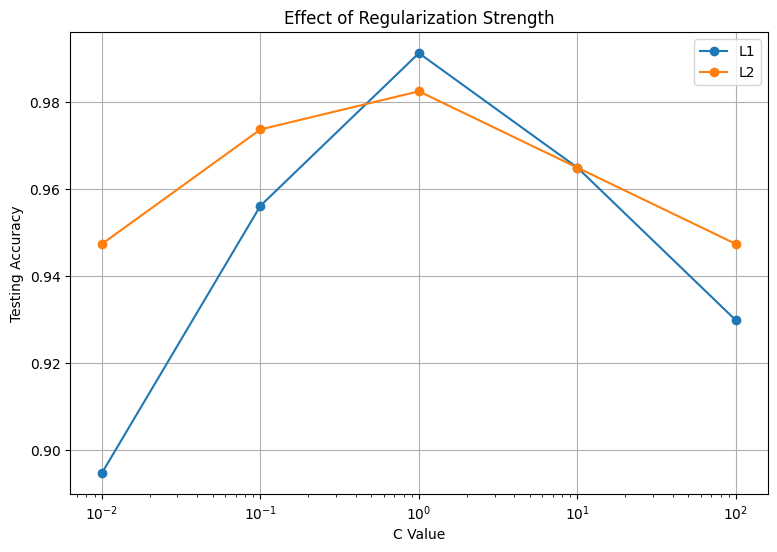

In [30]:
plt.figure(figsize=(9, 6))

plt.plot(
    C_values,
    l1_scores,
    marker="o",
    label="L1"
)

plt.plot(
    C_values,
    l2_scores,
    marker="o",
    label="L2"
)

plt.xscale("log")

plt.xlabel("C Value")
plt.ylabel("Testing Accuracy")
plt.title("Effect of Regularization Strength")

plt.legend()
plt.grid(True)

plt.show()

In [31]:
models_for_cv = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss"
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        verbosity=-1
    )
}

cv_results = []

for name, model in models_for_cv.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "CV Std": scores.std()
    })

cv_results = pd.DataFrame(cv_results)

cv_results

,Model,Mean CV Accuracy,CV Std
0,Decision Tree,0.917342,0.024195
1,Bagging,0.957895,0.038196
2,Gradient Boosting,0.963127,0.021024
3,XGBoost,0.964866,0.016619
4,LightGBM,0.970144,0.017167


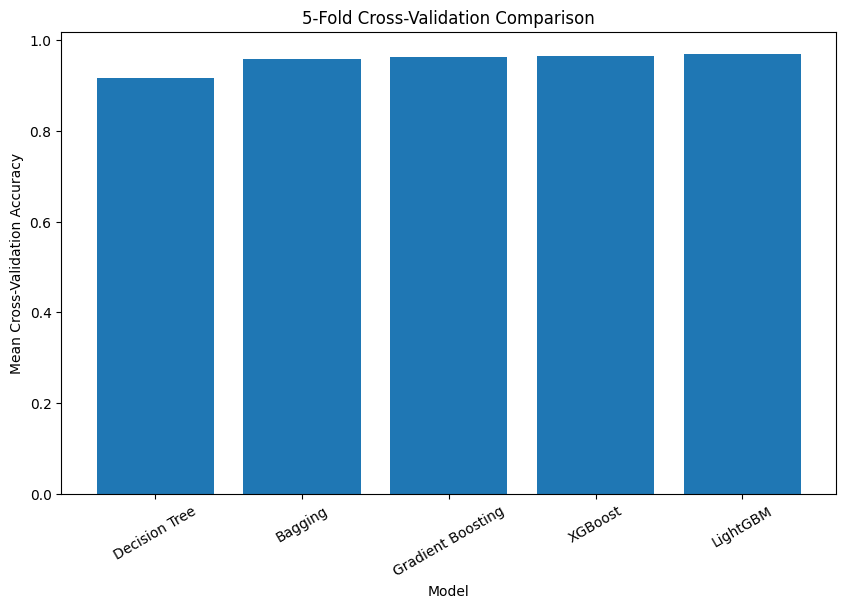

In [32]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_results["Model"],
    cv_results["Mean CV Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("5-Fold Cross-Validation Comparison")

plt.xticks(rotation=30)

plt.show()

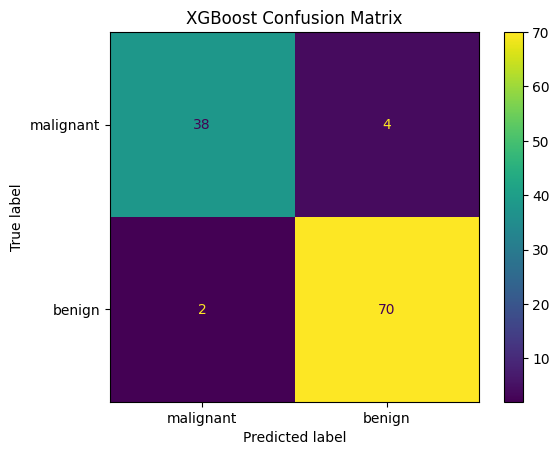

In [33]:
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_xgb
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot()

plt.title("XGBoost Confusion Matrix")
plt.show()

In [34]:
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=data.target_names
    )
)

              precision    recall  f1-score   support

   malignant       0.95      0.90      0.93        42
      benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



In [35]:
final_results = results[
    [
        "Model",
        "Training Accuracy",
        "Testing Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Generalization Gap"
    ]
]

final_results

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score,ROC-AUC,Generalization Gap
0,Decision Tree,1.0,0.912281,0.955882,0.902778,0.928571,0.915675,0.087719
1,Bagging,1.0,0.938596,0.945205,0.958333,0.951724,0.992725,0.061404
2,Gradient Boosting,1.0,0.956140,0.946667,0.986111,0.965986,0.990741,0.043860
3,XGBoost,1.0,0.947368,0.945946,0.972222,0.958904,0.993386,0.052632
4,LightGBM,1.0,0.964912,0.959459,0.986111,0.972603,0.989749,0.035088


In [36]:
print("""
CONCLUSION

This project demonstrated ensemble learning and model generalization
using the Breast Cancer Wisconsin dataset.

Bagging was demonstrated using multiple decision trees trained on
bootstrap samples.

Boosting was demonstrated using Gradient Boosting, XGBoost, and
LightGBM.

The bias-variance trade-off was studied by changing decision tree
complexity and comparing training and testing performance.

Overfitting was demonstrated using a highly complex decision tree,
while underfitting was demonstrated using a very shallow tree.

L1 and L2 regularization were demonstrated using Logistic Regression.

Cross-validation was also used to compare the consistency of the
different ensemble models.

The project demonstrates how ensemble methods and regularization can
be used to improve model generalization and control model complexity.
""")


CONCLUSION

This project demonstrated ensemble learning and model generalization
using the Breast Cancer Wisconsin dataset.

Bagging was demonstrated using multiple decision trees trained on
bootstrap samples.

Boosting was demonstrated using Gradient Boosting, XGBoost, and
LightGBM.

The bias-variance trade-off was studied by changing decision tree
complexity and comparing training and testing performance.

Overfitting was demonstrated using a highly complex decision tree,
while underfitting was demonstrated using a very shallow tree.

L1 and L2 regularization were demonstrated using Logistic Regression.

Cross-validation was also used to compare the consistency of the
different ensemble models.

The project demonstrates how ensemble methods and regularization can
be used to improve model generalization and control model complexity.

